# 1. Análisis exploratorio: crecimiento poblacional comunal en Chile

**Técnica asignada: clasificación.**

**Pregunta.** Con lo que se sabe de una comuna al inicio de un período intercensal (su tamaño, su estructura de edades y cuánto creció antes), ¿se puede clasificar si crecerá **al menos 1% anual** durante el período siguiente?

- Clase positiva (1): tasa anual ≥ 1%, es decir, *crecimiento alto*.
- Clase negativa (0): tasa anual < 1%, que incluye las comunas estancadas o que pierden población.

Tasa anual = (P_final / P_inicial)^(1/años) − 1. El umbral de 1% es una decisión del proyecto: está cerca de la mediana de las tasas y separa con claridad a las comunas que crecen de las estancadas o en declive.

Este notebook documenta la procedencia de los datos, su calidad, sus características y patrones, y las decisiones de limpieza, transformación y selección de variables. El experimento comparativo está en `02_experimento_clasificacion.ipynb`.

In [1]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG = ROOT / 'results/entrega'
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

perfiles = pd.read_csv(ROOT / 'results/crecimiento_v2/perfiles_censales.csv')
calidad = json.loads((ROOT / 'results/crecimiento_v2/calidad_datos.json').read_text())
UMBRAL = 0.01

def tasa_anual(p0, p1, anios):
    return (np.asarray(p1, float) / np.asarray(p0, float)) ** (1 / anios) - 1

def anio(y):
    return perfiles[perfiles.year == y].set_index('code').sort_index()


## 1.1 Procedencia

Todos los datos son **tabulados oficiales del INE** (Instituto Nacional de Estadísticas de Chile):

| Censo | Fuente | Archivo en `data/raw/ine/crecimiento/` |
|---|---|---|
| 1992 | REDATAM INE, población por comuna y edad | `edad_residencia_1992.html` |
| 2002 | REDATAM INE, población por comuna y edad (DPA actualizada) | `edad_residencia_2002.html` |
| 2017 | REDATAM INE, residentes habituales por comuna y edad | `edad_residencia_2017.html`, `residentes_2017.xlsx` |
| 2024 | Resultados oficiales Censo 2024 | `poblacion_2024.xlsx` |

Los archivos crudos están versionados en el repositorio junto con su manifiesto de descarga (URL, fecha y hash SHA-256). Los scripts `experiments/descargar_crecimiento.py` y `experiments/descargar_fuentes_v2.py` los vuelven a descargar. `experiments/crecimiento_censal.py` y `experiments/crecimiento_v2.py` construyen la tabla integrada `results/crecimiento_v2/perfiles_censales.csv`, que es la que se analiza aquí.

In [2]:
fuentes = json.loads((ROOT / 'data/raw/ine/crecimiento/fuentes.json').read_text())
print('Editor:', fuentes['publisher'], '| licencia:', fuentes['license'], '| descargado:', fuentes['retrieved_at'][:10])
pd.DataFrame([{'archivo': f['file'], 'base': f.get('params', {}).get('BASE', ''), 'url': f['url'],
               'sha256': str(f.get('sha256', ''))[:16] + '…'} for f in fuentes['files']])

Editor: Instituto Nacional de Estadísticas de Chile | licencia: CC BY-SA 4.0 | descargado: 2026-10-05


,archivo,base,url,sha256
0,edad_residencia_1992.html,CENSO_1992,https://redatam-ine.ine.cl/redbin/RpWebStats.e...,a6dd2b414fb0466b…
1,edad_residencia_2002.html,CENSO_2002,https://redatam-ine.ine.cl/redbin/RpWebStats.e...,24212f5052fd331b…
2,edad_residencia_2017.html,CENSO_2017,https://redatam-ine.ine.cl/redbin/RpWebStats.e...,efa35d98f0ee8522…
3,edad_local_2017.html,CENSO_2017,https://redatam-ine.ine.cl/redbin/RpWebStats.e...,996b8f65fac8ed7a…
4,poblacion_2024.xlsx,,https://censo2024.ine.gob.cl/wp-content/upload...,1f3a9c97a1b3defa…
5,residentes_2017.xlsx,,https://censo2024.ine.gob.cl/wp-content/upload...,ea5aa0f3a1bad6ac…


## 1.2 Estructura de la tabla integrada

Cada fila es una **comuna en un año censal**, con población total, menores de 15 años (`young`) y personas de 65 o más (`old`).

In [3]:
display(perfiles.head())
print(perfiles.dtypes)
display(perfiles.groupby('year').agg(comunas=('code', 'nunique'), poblacion_total=('population', 'sum'),
                                     mediana_comuna=('population', 'median'), minimo=('population', 'min'),
                                     maximo=('population', 'max')))

,code,name,region,region_code,key,year,population,young,old
0,15101,Arica,Arica y Parinacota,15,arica,1992,168561,50304,7887
1,15101,Arica,Arica y Parinacota,15,arica,2002,184914,47988,13059
2,15101,Arica,Arica y Parinacota,15,arica,2017,218612,47821,23797
3,15102,Camarones,Arica y Parinacota,15,camarones,1992,729,207,74
4,15102,Camarones,Arica y Parinacota,15,camarones,2002,999,246,116


code            int64
name           object
region         object
region_code     int64
key            object
year            int64
population      int64
young           int64
old             int64
dtype: object


,comunas,poblacion_total,mediana_comuna,minimo,maximo
year,,,,,
1992,315,11171717,14325.0,113,327402
2002,316,12499266,15957.5,27,467861
2017,316,14351217,17356.0,100,517384
2024,316,15340117,19171.0,60,503635


## 1.3 Calidad de los datos

Se revisan valores faltantes, duplicados, coherencia interna, comunas excluidas y concordancia con una publicación independiente del INE.

In [4]:
chequeos = {
    'valores faltantes': int(perfiles.isna().sum().sum()),
    'filas duplicadas (code, year)': int(perfiles.duplicated(['code', 'year']).sum()),
    'menores + mayores > población': int((perfiles.young + perfiles.old > perfiles.population).sum()),
    'población <= 0': int((perfiles.population <= 0).sum()),
    'comunas incluidas': calidad['included_communes'],
    'comunas excluidas': len(calidad['exclusions']),
    'comunas contrastadas en 2017 con publicación independiente': calidad['independent_2017_check']['compared_communes'],
    'diferencias encontradas en ese contraste': len(calidad['independent_2017_check']['differences']),
}
pd.Series(chequeos, name='resultado').to_frame()

,resultado
valores faltantes,0
"filas duplicadas (code, year)",0
menores + mayores > población,0
población <= 0,0
comunas incluidas,316
comunas excluidas,30
comunas contrastadas en 2017 con publicación independiente,346
diferencias encontradas en ese contraste,0


No hay faltantes, duplicados ni conteos incoherentes. El contraste con la publicación independiente del INE de residentes 2017 no encontró diferencias.

El principal problema de calidad es **territorial**: entre 1992 y 2024 se crearon comunas y se movieron límites. Si se comparara una comuna cuyo territorio cambió, se mediría un "crecimiento" falso. Por eso se excluyen **30 comunas** afectadas (ver la tabla siguiente). Temuco y Padre Las Casas se recuperaron con fuentes legales y la publicación del INE con DPA actualizada; de Padre Las Casas no se usa el dato de 1992.

In [5]:
excl = pd.DataFrame(calidad['exclusions'])[['code', 'name', 'region', 'reason']]
display(excl.groupby('reason').name.apply(lambda s: ', '.join(s)).to_frame('comunas'))
print('Faltantes por año (comunas sin dato):')
print(316 - perfiles.groupby('year').code.nunique())

,comunas
reason,
Cambio de límite de Ley 20.721 (2014),"Paihuano, Vicuña"
Cambios de límites de Ley 20.578 (2012),"Combarbalá, Punitaqui, La Pintana, Puente Alto..."
Creación de comunas en 2004 y sus comunas de origen,"Iquique, Alto Hospicio, Talcahuano, Hualpén, S..."
Creación o división comunal 1994–1996; geografía histórica pendiente de certificar,"Concón, Viña del Mar, Padre Hurtado, Peñaflor,..."
Dos etiquetas Caldera en REDATAM 1992; no corregir ni unir por conjetura,"Caldera, Calera"


Faltantes por año (comunas sin dato):
year
1992    1
2002    0
2017    0
2024    0
Name: code, dtype: int64


## 1.4 Construcción de la variable objetivo

Se calculan las tasas anuales de los tres períodos intercensales.

In [6]:
p92, p02, p17, p24 = anio(1992), anio(2002), anio(2017), anio(2024)
tasas = pd.DataFrame({
    '1992-2002': tasa_anual(p92.population, p02.population.reindex(p92.index), 10),
}, index=p92.index).reindex(p02.index)
tasas['2002-2017'] = tasa_anual(p02.population, p17.population, 15)
tasas['2017-2024'] = tasa_anual(p17.population, p24.population, 7)
tasas.insert(0, 'region', p02.region)
tasas.insert(0, 'comuna', p02.name)
display(tasas.describe().T)
balance = (tasas[['1992-2002', '2002-2017', '2017-2024']] >= UMBRAL).apply(lambda c: c[tasas[c.name].notna()].value_counts()).T
balance.columns = ['< 1% (0)', '≥ 1% (1)']
balance['% positiva'] = (100 * balance['≥ 1% (1)'] / balance.sum(axis=1)).round(1)
balance

,count,mean,std,min,25%,50%,75%,max
1992-2002,315.0,0.007145,0.018657,-0.133380,-0.001887,0.006001,0.015049,0.118767
2002-2017,316.0,0.006450,0.014229,-0.054782,-0.001098,0.005700,0.011994,0.091212
2017-2024,316.0,0.008583,0.019939,-0.167419,0.004122,0.009485,0.016114,0.067743


,< 1% (0),≥ 1% (1),% positiva
1992-2002,190,125,39.7
2002-2017,218,98,31.0
2017-2024,165,151,47.8


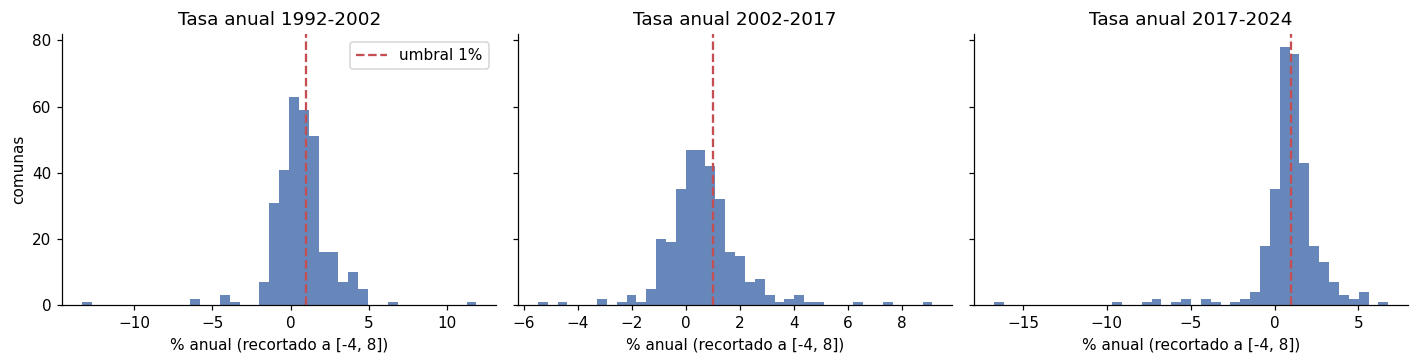

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, col in zip(axes, ['1992-2002', '2002-2017', '2017-2024']):
    v = 100 * tasas[col].dropna().clip(-4, 8)
    ax.hist(v, bins=40, color='#4C72B0', alpha=.85)
    ax.axvline(100 * UMBRAL, color='#C44E52', ls='--', label='umbral 1%')
    ax.set_title(f'Tasa anual {col}')
    ax.set_xlabel('% anual (recortado a [-4, 8])')
axes[0].set_ylabel('comunas'); axes[0].legend()
plt.tight_layout(); plt.savefig(FIG / 'eda_distribucion_tasas.png', bbox_inches='tight'); plt.show()

**Lectura.**
- El **balance de clases cambia** entre períodos: 40% de comunas positivas en 1992–2002, **31% en 2002–2017** (el período de entrenamiento) y **48% en 2017–2024** (el de prueba). Por ese desbalance moderado y cambiante, el experimento usa **F1 macro** y pesos de clase balanceados en lugar de la exactitud simple.
- Las tasas se concentran entre 0 y 2% anual. Muchas comunas quedan cerca del umbral, lo que hace difícil clasificarlas.
- Hay colas de comunas en fuerte declive y otras de crecimiento muy rápido.

## 1.5 Patrones relevantes

### Persistencia del crecimiento
¿Las comunas que crecieron en el período anterior siguen creciendo?

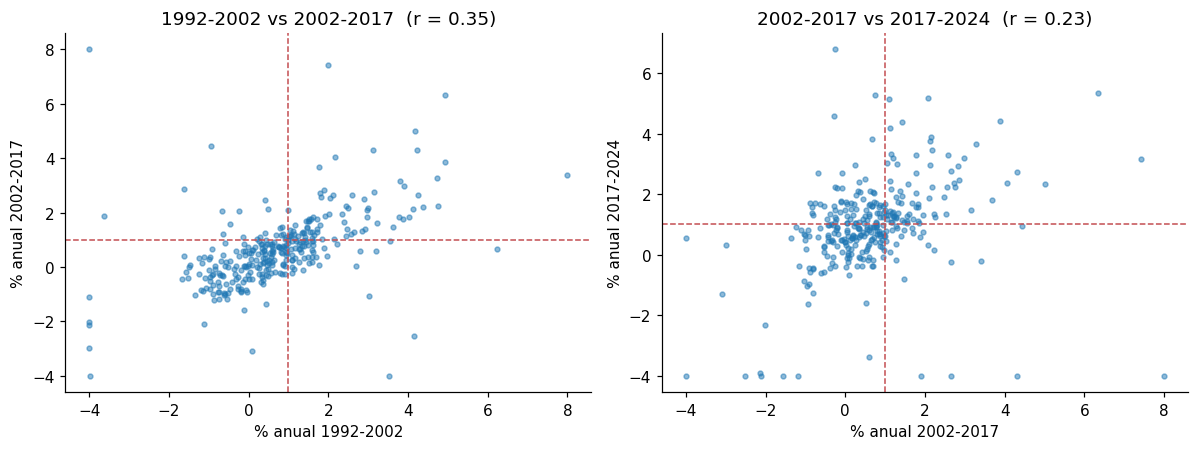

2002-2017 ≥1%,False,True
1992-2002 ≥1%,,
False,169,21
True,49,76


2017-2024 ≥1%,False,True
2002-2017 ≥1%,,
False,141,77
True,24,74


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (a, b) in zip(axes, [('1992-2002', '2002-2017'), ('2002-2017', '2017-2024')]):
    d = tasas[[a, b]].dropna() * 100
    d = d.clip(-4, 8)
    ax.scatter(d[a], d[b], s=10, alpha=.5)
    ax.axvline(1, color='#C44E52', ls='--', lw=1); ax.axhline(1, color='#C44E52', ls='--', lw=1)
    r = tasas[[a, b]].corr().iloc[0, 1]
    ax.set_title(f'{a} vs {b}  (r = {r:.2f})'); ax.set_xlabel(f'% anual {a}'); ax.set_ylabel(f'% anual {b}')
plt.tight_layout(); plt.savefig(FIG / 'eda_persistencia.png', bbox_inches='tight'); plt.show()

for a, b in [('1992-2002', '2002-2017'), ('2002-2017', '2017-2024')]:
    d = tasas[[a, b]].dropna()
    t = pd.crosstab(d[a] >= UMBRAL, d[b] >= UMBRAL, rownames=[f'{a} ≥1%'], colnames=[f'{b} ≥1%'])
    display(t)

El crecimiento pasado está **correlacionado** con el siguiente (Spearman 0,65 entre 1992–2002 y 2002–2017), pero muchas comunas cambian de clase. Entre 2002–2017 y 2017–2024, **77 comunas pasaron a crecer ≥1%** aunque antes no lo hacían, y 24 dejaron de hacerlo. Esto justifica usar el crecimiento previo como variable, y también compararse contra una línea base de *continuidad* (predecir la misma clase del período anterior).

### Tamaño y estructura etaria

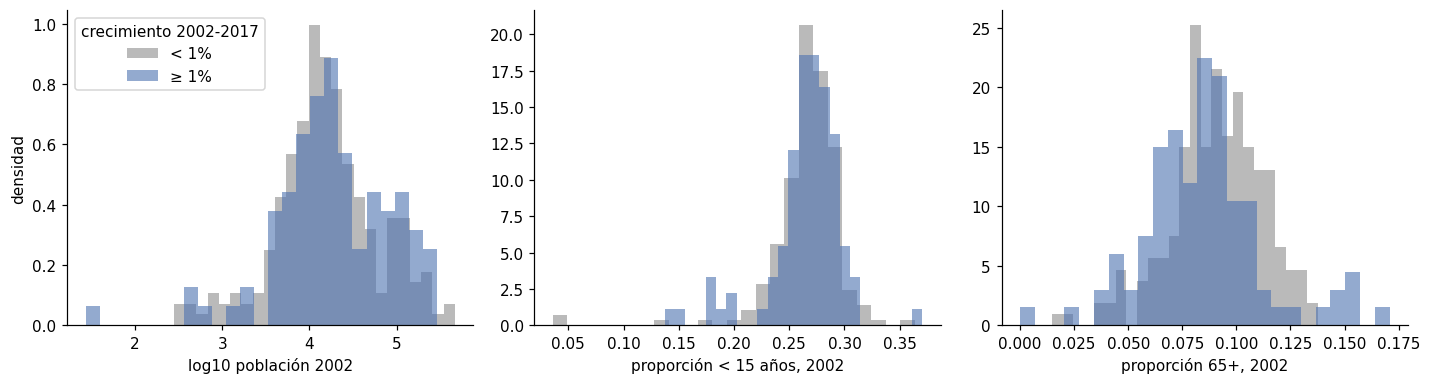

,log_pob,prop_menores_15,prop_65_mas
clase,,,
0,4.174957,0.269246,0.092048
1,4.243235,0.271090,0.084838


In [9]:
base = p02.copy()
base['tasa_siguiente'] = tasas['2002-2017']
base['log_pob'] = np.log10(base.population)
base['prop_menores_15'] = base.young / base.population
base['prop_65_mas'] = base.old / base.population
base['clase'] = (base.tasa_siguiente >= UMBRAL).astype(int)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, lab in zip(axes, ['log_pob', 'prop_menores_15', 'prop_65_mas'],
                        ['log10 población 2002', 'proporción < 15 años, 2002', 'proporción 65+, 2002']):
    for c, color, name in [(0, '#8C8C8C', '< 1%'), (1, '#4C72B0', '≥ 1%')]:
        ax.hist(base.loc[base.clase == c, col], bins=25, alpha=.6, color=color, label=name, density=True)
    ax.set_xlabel(lab)
axes[0].legend(title='crecimiento 2002-2017'); axes[0].set_ylabel('densidad')
plt.tight_layout(); plt.savefig(FIG / 'eda_variables_por_clase.png', bbox_inches='tight'); plt.show()
display(base.groupby('clase')[['log_pob', 'prop_menores_15', 'prop_65_mas']].median())

- La **proporción de 65 años o más** es la variable de un solo censo que más separa las clases: las comunas envejecidas crecen menos (Spearman −0,25 con la tasa siguiente).
- El **tamaño** tiene una relación positiva pero débil (Spearman 0,18).
- La proporción de menores de 15 años casi no separa las clases (0,03).
- Ninguna variable de un solo censo es tan informativa como el **crecimiento previo** (0,65). Esto anticipa que el modelo sin historia rendirá poco.

### Envejecimiento general y diferencias regionales

In [10]:
edad = perfiles.groupby('year')[['population', 'young', 'old']].sum()
edad['% < 15'] = 100 * edad.young / edad.population
edad['% 65+'] = 100 * edad.old / edad.population
display(edad[['population', '% < 15', '% 65+']].round(1))
reg = tasas.groupby('region')[['2002-2017', '2017-2024']].apply(lambda d: (d >= UMBRAL).mean() * 100).round(0)
reg.columns = ['% comunas ≥1% 2002-17', '% comunas ≥1% 2017-24']
reg.sort_values('% comunas ≥1% 2017-24', ascending=False)

,population,% < 15,% 65+
year,,,
1992,11171717,29.3,6.7
2002,12499266,25.7,8.3
2017,14351217,19.9,11.6
2024,15340117,17.7,14.2


,% comunas ≥1% 2002-17,% comunas ≥1% 2017-24
region,,
Ñuble,11.0,84.0
Tarapacá,40.0,80.0
Libertador General Bernardo O'Higgins,30.0,64.0
Maule,25.0,64.0
Valparaíso,66.0,63.0
Los Ríos,8.0,50.0
Los Lagos,14.0,43.0
La Araucanía,14.0,41.0
Metropolitana de Santiago,54.0,40.0


**Cambio de régimen regional.** El crecimiento se desplazó entre períodos. En Ñuble, el 11% de las comunas creció ≥1% en 2002–2017 y el 84% en 2017–2024; algo parecido ocurrió en Maule, O'Higgins y Los Ríos. En la Región Metropolitana la proporción bajó de 54% a 40%. Un modelo entrenado con un único período no puede anticipar ese desplazamiento, lo que será la principal fuente de error.

In [11]:
corr = base[['log_pob', 'prop_menores_15', 'prop_65_mas', 'tasa_siguiente']].copy()
corr['crecimiento_previo'] = tasas['1992-2002']
corr.corr(method='spearman').round(2)

,log_pob,prop_menores_15,prop_65_mas,tasa_siguiente,crecimiento_previo
log_pob,1.00,-0.09,-0.23,0.18,0.19
prop_menores_15,-0.09,1.00,-0.47,0.03,0.16
prop_65_mas,-0.23,-0.47,1.00,-0.25,-0.43
tasa_siguiente,0.18,0.03,-0.25,1.00,0.65
crecimiento_previo,0.19,0.16,-0.43,0.65,1.00


## 1.6 Decisiones de limpieza, transformación y selección de variables

**Limpieza**
- Se excluyen 30 comunas con cambios territoriales (creaciones o modificaciones de límites) entre censos: compararlas mediría cambios de límites, no crecimiento. No se imputan poblaciones ni se reparten habitantes por conjetura.
- Se usa la población **residente habitual** con comuna identificada, la definición comparable entre censos. No se imputan personas sin comuna conocida.

**Transformación**
- Tasa **anualizada** (geométrica), porque los períodos duran 10, 15 y 7 años y solo así son comparables.
- **Logaritmo** de la población, porque va de 27 a más de 500 mil habitantes y el logaritmo reduce la asimetría.
- **Proporciones** de menores de 15 años y de 65 o más, en lugar de conteos, para separar la estructura etaria del tamaño.
- Objetivo **binario** con umbral 1%: la pregunta práctica es si una comuna crecerá de forma sostenida, no el número exacto de habitantes.

**Selección de variables (candidatas)**
1. `log_poblacion` al inicio del período.
2. `proporcion_menores_15` al inicio.
3. `proporcion_65_mas` al inicio.
4. `crecimiento_previo`: la tasa anual del período anterior.
5. y 6. Cambio anual de las dos proporciones etarias en el período anterior.

**Excluidas a propósito:** el código y el nombre de la comuna (son identificadores, no información), la región (con tan pocos casos por región se memorizaría) y la población final o la tasa del propio período (eso es la respuesta, y usarlas sería *filtración de información*). Todas las entradas usan solo censos **anteriores o iguales** al inicio del período.

El experimento decide si las variables 5 y 6 aportan.